# Analisis dan rekomendasi untuk warung

**Agentris · A26-CS193 · Jauza, Data Science**

Pak Tommy mencatat pemasukan dan belanja warung dalam catatan terpisah. Agentris perlu menyatukan catatan tersebut agar beliau bisa melihat uang masuk, uang keluar, serta selisihnya pada periode yang sama. Jika rincian penjualan disimpan, catatan itu juga bisa menunjukkan hari dengan pesanan terbanyak dan menu yang paling sering dipesan.

Notebook ini memakai dua CSV bersih dari Mufid. Keduanya berisi **data simulasi Agustus–Oktober 2026**. Hasilnya menunjukkan cara kerja analisis pada data uji. Catatan primer WhatsApp dipakai sebagai konteks wawancara. Tanggal lengkap kedua catatan dan rincian menu per penjualan masih belum tersedia, sehingga catatan tersebut tetap di luar perhitungan.

## Cara menjalankan

1. Buka repositori Agentris. Dari folder akar repo, jalankan `python -m pip install -r data-science/requirements.txt`.
2. Buka notebook dengan kernel Python dari lingkungan yang sama, lalu pilih Run All. CSV dibaca dari `data-science/datasets/processed`.
3. Untuk mengubah periode analisis menu, isi `BULAN` dengan format `YYYY-MM`, misalnya `"2026-09"`. Nilai `None` memilih bulan penjualan terbaru. Rekap bulanan dan grafik harian tetap memakai seluruh periode CSV.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, StrMethodFormatter
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display


BULAN = None

cwd = Path.cwd()
data_science = next(
    (
        candidate
        for parent in (cwd, *cwd.parents)
        for candidate in (parent, parent / "data-science")
        if (candidate / "datasets" / "processed").is_dir()
    ),
    None,
)
if data_science is None:
    raise FileNotFoundError(
        "Folder datasets/processed tidak ditemukan. Buka kernel dari repositori Agentris."
    )
folder_data = data_science / "datasets" / "processed"

NAMA_BULAN = (
    "Januari", "Februari", "Maret", "April", "Mei", "Juni",
    "Juli", "Agustus", "September", "Oktober", "November", "Desember",
)
sns.set_theme(style="whitegrid", context="notebook", rc={"figure.dpi": 135})


def rupiah(nilai):
    return f"Rp{nilai:,.0f}".replace(",", ".")


def nama_bulan(periode):
    return f"{NAMA_BULAN[periode.month - 1]} {periode.year}"


def tanggal_indonesia(tanggal):
    return f"{tanggal.day} {nama_bulan(tanggal)}"

## Data yang dipakai

| Sumber | Satu baris mewakili | Kolom untuk analisis |
| :--- | :--- | :--- |
| `penjualan_sintetis_clean.csv` | Satu menu dalam transaksi penjualan | Tanggal, ID transaksi, ID detail, menu, jumlah, harga satuan, subtotal, total transaksi |
| `pengeluaran_sintetis_clean.csv` | Satu catatan pengeluaran | Tanggal, ID pengeluaran, nominal |

Satu nota bisa berisi beberapa menu. Karena total nota terulang di setiap barisnya, pemasukan dihitung dari subtotal setiap menu. Jumlah transaksi dihitung dari ID nota yang berbeda. Notebook 01–03 mendokumentasikan pengumpulan, pembersihan, dan validasi data. Pemeriksaan di bawah memastikan CSV yang dibaca masih memenuhi asumsi untuk rekap.

In [2]:
def baca_csv(nama_file, id_baris, kolom_teks, kolom_angka):
    kolom = [id_baris, "tanggal", *kolom_teks, *kolom_angka]
    data = pd.read_csv(folder_data / nama_file, usecols=kolom, dtype="string")
    if data.empty or data.isna().any().any():
        raise ValueError(f"{nama_file} kosong atau memiliki sel wajib yang hilang.")
    if data.apply(lambda kolom: kolom.str.strip().eq("").any()).any():
        raise ValueError(f"{nama_file} memiliki sel wajib yang berisi spasi saja.")
    if data[id_baris].duplicated().any():
        raise ValueError(f"{nama_file} memiliki {id_baris} yang berulang.")
    if not data["tanggal"].str.fullmatch(r"\d{4}-\d{2}-\d{2}").all():
        raise ValueError(f"{nama_file} harus memakai tanggal berformat YYYY-MM-DD.")

    data["tanggal"] = pd.to_datetime(data["tanggal"], format="%Y-%m-%d")
    data[kolom_angka] = data[kolom_angka].astype("int64")
    if data[kolom_angka].le(0).any().any():
        raise ValueError(f"Jumlah dan nominal dalam {nama_file} harus positif.")
    return data


penjualan = baca_csv(
    "penjualan_sintetis_clean.csv",
    id_baris="id_detail",
    kolom_teks=["id_transaksi", "jenis_makanan"],
    kolom_angka=["jumlah", "harga_satuan", "subtotal", "total_transaksi"],
)
pengeluaran = baca_csv(
    "pengeluaran_sintetis_clean.csv",
    id_baris="no",
    kolom_teks=[],
    kolom_angka=["total"],
)

if not penjualan["subtotal"].eq(penjualan["jumlah"] * penjualan["harga_satuan"]).all():
    raise ValueError("Ada subtotal penjualan yang berbeda dari jumlah × harga satuan.")

per_nota = penjualan.groupby("id_transaksi").agg(
    tanggal=("tanggal", "first"),
    jumlah_tanggal=("tanggal", "nunique"),
    subtotal=("subtotal", "sum"),
    total_nota=("total_transaksi", "first"),
    jumlah_total=("total_transaksi", "nunique"),
)
if not (per_nota["jumlah_tanggal"].eq(1) & per_nota["jumlah_total"].eq(1)).all():
    raise ValueError("Satu ID nota memiliki beberapa tanggal atau total yang berbeda.")
if not per_nota["subtotal"].eq(per_nota["total_nota"]).all():
    raise ValueError("Jumlah subtotal pada satu nota berbeda dari total nota.")

ringkasan = pd.DataFrame(
    [
        {
            "Sumber data uji": label,
            "Baris": len(data),
            "ID transaksi/catatan": jumlah_id,
            "Awal catatan": tanggal_indonesia(data["tanggal"].min()),
            "Akhir catatan": tanggal_indonesia(data["tanggal"].max()),
        }
        for label, data, jumlah_id in (
            ("Penjualan", penjualan, len(per_nota)),
            ("Pengeluaran", pengeluaran, pengeluaran["no"].nunique()),
        )
    ]
)
display(ringkasan.style.hide(axis="index"))

Sumber data uji,Baris,ID transaksi/catatan,Awal catatan,Akhir catatan
Penjualan,2573,1148,1 Agustus 2026,31 Oktober 2026
Pengeluaran,457,457,1 Agustus 2026,31 Oktober 2026


## PB-01 sampai PB-03 · Rekap per bulan

PB-01 menanyakan total pemasukan yang tercatat setiap bulan. PB-02 menanyakan total pengeluaran. Untuk PB-03, kurangi pengeluaran dari pemasukan pada bulan kalender yang sama. Tabel juga menunjukkan berapa hari yang memiliki catatan dari masing-masing sumber. Jika salah satu sumber kosong sepanjang bulan, total sumber itu dan selisih bulan tersebut ditampilkan sebagai data yang belum tersedia.

Selisih ini mengikuti uang masuk dan uang keluar yang tersedia di catatan. Untuk menghitung laba usaha, Pak Tommy perlu memeriksa kelengkapan pendapatan dan memasukkan semua biaya yang terkait dengan periode tersebut.

Bulan,Pemasukan,Pengeluaran,Selisih tercatat,Hari tercatat (masuk),Hari tercatat (keluar)
Agustus 2026,Rp9.193.000,Rp3.879.000,Rp5.314.000,31/31,31/31
September 2026,Rp8.795.500,Rp3.051.500,Rp5.744.000,30/30,30/30
Oktober 2026,Rp8.501.500,Rp3.691.500,Rp4.810.000,31/31,31/31


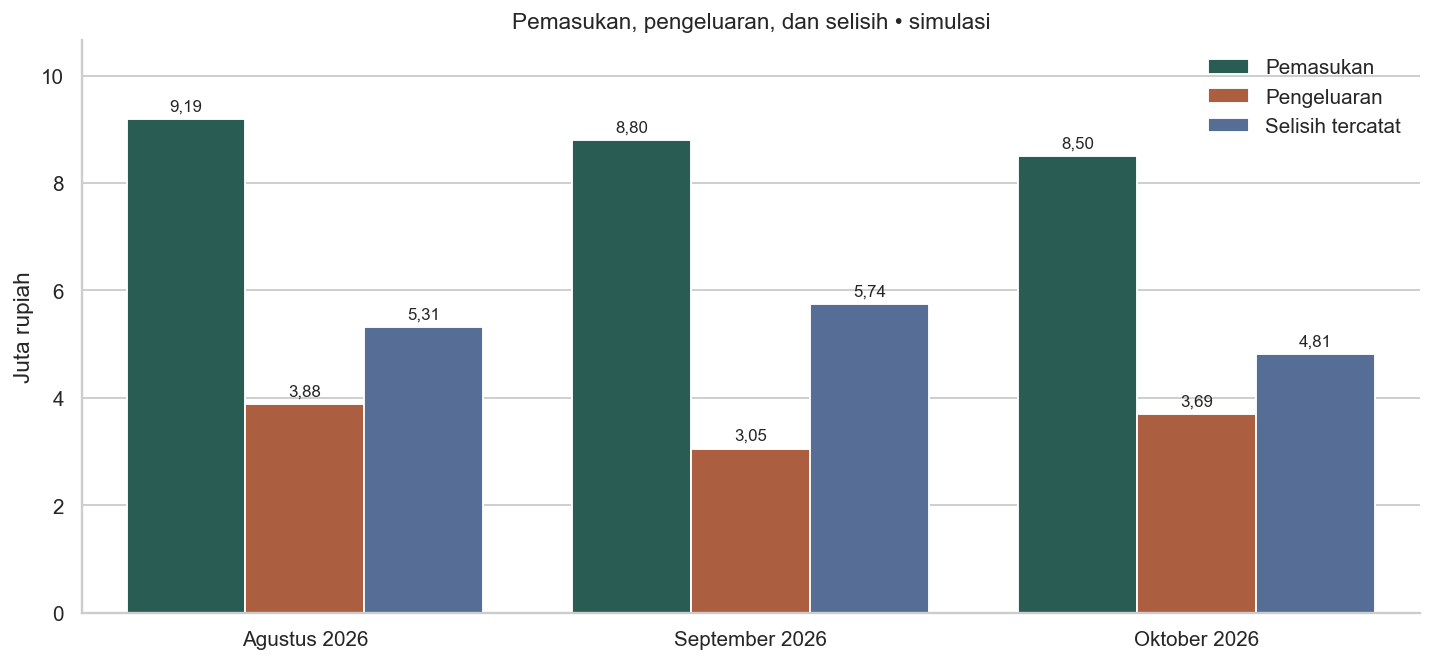

In [3]:
def rekap_bulanan(data_jual, data_keluar):
    jual_per_bulan = data_jual.groupby(data_jual["tanggal"].dt.to_period("M")).agg(
        pemasukan=("subtotal", "sum"),
        hari_pemasukan=("tanggal", "nunique"),
    )
    keluar_per_bulan = data_keluar.groupby(data_keluar["tanggal"].dt.to_period("M")).agg(
        pengeluaran=("total", "sum"),
        hari_pengeluaran=("tanggal", "nunique"),
    )
    awal = min(data_jual["tanggal"].min(), data_keluar["tanggal"].min())
    akhir = max(data_jual["tanggal"].max(), data_keluar["tanggal"].max())
    periode = pd.period_range(awal, akhir, freq="M", name="bulan")
    rekap = jual_per_bulan.join(keluar_per_bulan, how="outer").reindex(periode)
    kolom_hari = ["hari_pemasukan", "hari_pengeluaran"]
    rekap[kolom_hari] = rekap[kolom_hari].fillna(0).astype("int64")
    rekap[["pemasukan", "pengeluaran"]] = rekap[["pemasukan", "pengeluaran"]].astype("Int64")
    rekap["selisih"] = rekap["pemasukan"] - rekap["pengeluaran"]
    rekap["hari_kalender"] = rekap.index.days_in_month
    return rekap


bulanan = rekap_bulanan(penjualan, pengeluaran)
label_nominal = {
    "pemasukan": "Pemasukan",
    "pengeluaran": "Pengeluaran",
    "selisih": "Selisih tercatat",
}
tabel_bulanan = bulanan[list(label_nominal)].rename(columns=label_nominal)
tabel_bulanan.insert(0, "Bulan", bulanan.index.map(nama_bulan))
tabel_bulanan["Hari tercatat (masuk)"] = (
    bulanan["hari_pemasukan"].astype(str) + "/" + bulanan["hari_kalender"].astype(str)
)
tabel_bulanan["Hari tercatat (keluar)"] = (
    bulanan["hari_pengeluaran"].astype(str) + "/" + bulanan["hari_kalender"].astype(str)
)
display(
    tabel_bulanan.style
    .format(dict.fromkeys(label_nominal.values(), rupiah), na_rep="Belum tersedia")
    .hide(axis="index")
)

data_grafik = tabel_bulanan.melt(
    id_vars="Bulan", value_vars=list(label_nominal.values()),
    var_name="Jenis", value_name="Nominal",
).dropna(subset=["Nominal"])
data_grafik["Juta rupiah"] = data_grafik["Nominal"].astype(float) / 1_000_000

fig, ax = plt.subplots(figsize=(10.5, 4.8), layout="constrained")
sns.barplot(
    data=data_grafik, x="Bulan", y="Juta rupiah", hue="Jenis", errorbar=None,
    order=tabel_bulanan["Bulan"].tolist(),
    palette={"Pemasukan": "#206658", "Pengeluaran": "#BE572E", "Selisih tercatat": "#4C6B9F"},
    ax=ax,
)
for batang in ax.containers:
    ax.bar_label(
        batang, fmt=lambda nilai: f"{nilai:.2f}".replace(".", ","), padding=3, fontsize=9,
    )
ax.set(title="Pemasukan, pengeluaran, dan selisih • simulasi", xlabel="", ylabel="Juta rupiah")
ax.margins(y=0.16)
ax.axhline(0, color="#475569", linewidth=0.8)
ax.legend(title="", frameon=False)
sns.despine(ax=ax)
plt.show()

In [4]:
bulan_terakhir = bulanan.dropna(subset=["selisih"]).tail(1)
if bulan_terakhir.empty:
    display(Markdown("Belum ada bulan dengan catatan pemasukan dan pengeluaran sekaligus."))
else:
    periode = bulan_terakhir.index[0]
    angka = bulan_terakhir.iloc[0]
    display(Markdown(
        f"Pada bulan terakhir dengan kedua jenis catatan, **{nama_bulan(periode)}**, "
        f"pemasukan pada data uji sebesar **{rupiah(angka['pemasukan'])}** dan pengeluaran "
        f"sebesar **{rupiah(angka['pengeluaran'])}**. Selisih tercatat "
        f"**{rupiah(angka['selisih'])}**."
    ))

Pada bulan terakhir dengan kedua jenis catatan, **Oktober 2026**, pemasukan pada data uji sebesar **Rp8.501.500** dan pengeluaran sebesar **Rp3.691.500**. Selisih tercatat **Rp4.810.000**.

## PB-04 · Hari dengan jumlah transaksi penjualan terbanyak

Hitung ID nota yang berbeda untuk setiap tanggal. Titik oranye menandai semua tanggal yang berbagi posisi tertinggi. Tanggal tanpa catatan penjualan tidak diberi titik karena CSV ini tidak memberi informasi jam atau hari buka warung.

Tanggal,Jumlah nota
7 Oktober 2026,20
10 Oktober 2026,20
11 Oktober 2026,20
16 Oktober 2026,20


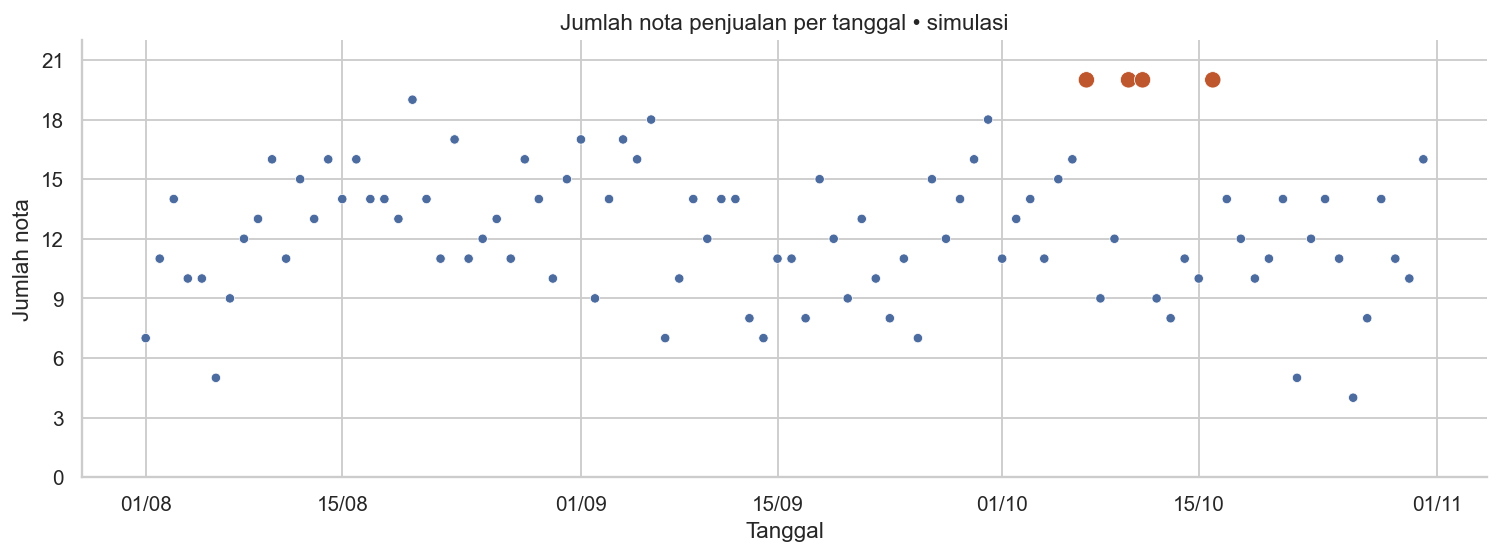

Rekor pada data uji adalah **20 nota**. Jumlah itu tercatat pada 7 Oktober 2026, 10 Oktober 2026, 11 Oktober 2026, 16 Oktober 2026.

In [5]:
harian = per_nota.groupby("tanggal").size().rename("transaksi").reset_index()
terbanyak = harian["transaksi"].max()
harian["puncak"] = harian["transaksi"].eq(terbanyak)
hari_puncak = harian.loc[harian["puncak"], ["tanggal", "transaksi"]]
tabel_puncak = hari_puncak.rename(columns={"tanggal": "Tanggal", "transaksi": "Jumlah nota"})
display(tabel_puncak.style.format({"Tanggal": tanggal_indonesia}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
sns.scatterplot(
    data=harian, x="tanggal", y="transaksi", hue="puncak", size="puncak",
    palette={False: "#4C6B9F", True: "#BE572E"}, sizes={False: 25, True: 76},
    legend=False, ax=ax,
)
ax.set(
    title="Jumlah nota penjualan per tanggal • simulasi",
    xlabel="Tanggal", ylabel="Jumlah nota", ylim=(0, terbanyak + 2),
)
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=8))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
sns.despine(ax=ax)
plt.show()

tanggal_puncak = ", ".join(hari_puncak["tanggal"].map(tanggal_indonesia))
display(Markdown(
    f"Rekor pada data uji adalah **{terbanyak} nota**. Jumlah itu tercatat pada {tanggal_puncak}."
))

## PB-05 · Menu dengan jumlah terjual terbanyak

Ambil detail penjualan pada bulan yang dipilih, kelompokkan menurut nama menu, lalu jumlahkan kolom `jumlah`. Grafik menunjukkan lima menu teratas beserta menu lain yang jumlahnya sama dengan posisi kelima. Takaran mengikuti satuan jual di CSV, termasuk minuman.

Peringkat,Menu,Unit terjual
1,Soto ayam,115
2,Teh es,113
3,Jeruk es,98
4,Soto sapi,68
5,Nasi goreng telur,46
5,Pecel lele,46
5,Soto ayam bungkus + nasi,46


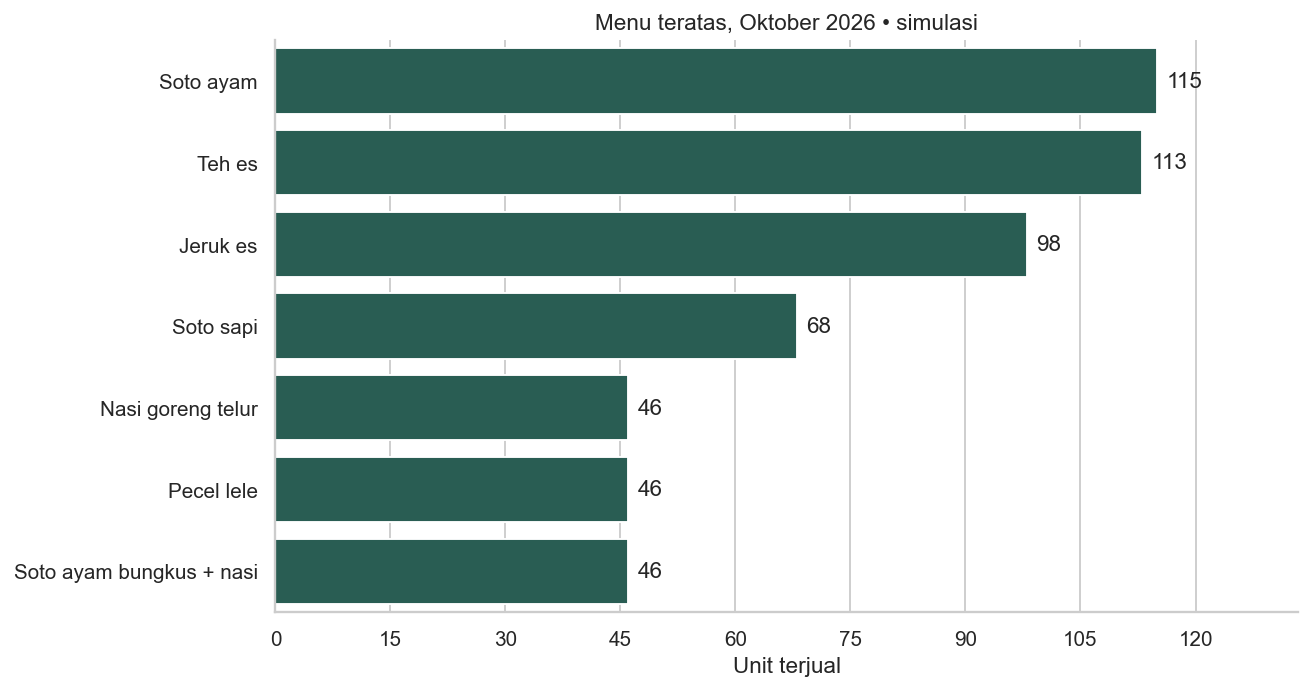

Pada simulasi **Oktober 2026**, posisi pertama ditempati **Soto ayam** dengan **115 unit** per menu.

In [6]:
bulan_jual = penjualan["tanggal"].dt.to_period("M")
periode_menu = bulan_jual.max() if BULAN is None else pd.Period(BULAN, freq="M")
penjualan_pilihan = penjualan.loc[bulan_jual.eq(periode_menu)]
if penjualan_pilihan.empty:
    bulan_tersedia = ", ".join(str(bulan) for bulan in sorted(bulan_jual.unique()))
    raise ValueError(f"Penjualan untuk {periode_menu} belum tersedia. Pilih {bulan_tersedia}.")

menu = (
    penjualan_pilihan.groupby("jenis_makanan", as_index=False)
    .agg(terjual=("jumlah", "sum"))
    .sort_values(["terjual", "jenis_makanan"], ascending=[False, True])
)
menu["peringkat"] = menu["terjual"].rank(method="min", ascending=False).astype("int64")
menu_teratas = menu.loc[menu["peringkat"].le(5)]
tabel_menu = menu_teratas[["peringkat", "jenis_makanan", "terjual"]].rename(
    columns={"peringkat": "Peringkat", "jenis_makanan": "Menu", "terjual": "Unit terjual"}
)
display(tabel_menu.style.hide(axis="index"))

fig, ax = plt.subplots(figsize=(9.6, max(3.5, 0.5 * len(menu_teratas) + 1.5)), layout="constrained")
sns.barplot(
    data=menu_teratas, x="terjual", y="jenis_makanan", color="#206658", errorbar=None, ax=ax,
)
ax.bar_label(ax.containers[0], fmt=StrMethodFormatter("{x:.0f}"), padding=5)
ax.set(title=f"Menu teratas, {nama_bulan(periode_menu)} • simulasi", xlabel="Unit terjual", ylabel="")
ax.margins(x=0.16)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
sns.despine(ax=ax)
plt.show()

pemenang = menu.loc[menu["peringkat"].eq(1)]
nama_menu = ", ".join(pemenang["jenis_makanan"])
jumlah_menu = pemenang["terjual"].iloc[0]
display(Markdown(
    f"Pada simulasi **{nama_bulan(periode_menu)}**, posisi pertama ditempati "
    f"**{nama_menu}** dengan **{jumlah_menu} unit** per menu."
))

## Cek hasil sebelum dipakai tim

Untuk setiap bulan, cocokkan pemasukan dari subtotal dengan total nota yang sudah dijadikan satu baris per ID. Jumlah transaksi juga harus sama dengan jumlah ID unik. Untuk uji terpisah dari Project Plan, masukkan Rp20.000 dan Rp10.000 di bulan pertama, lalu sisipkan transaksi lain di bulan berikutnya. Selisih bulan pertama harus tetap Rp10.000. Uji ini memeriksa fungsi rekap notebook. Tim bisa memakai angka yang sama ketika menguji chat dan dasbor.

In [7]:
total_dari_nota = per_nota.groupby(per_nota["tanggal"].dt.to_period("M"))["total_nota"].sum()
pd.testing.assert_series_equal(
    bulanan["pemasukan"].dropna().astype("int64"),
    total_dari_nota.rename_axis("bulan"),
    check_names=False,
)
if harian["transaksi"].sum() != penjualan["id_transaksi"].nunique():
    raise AssertionError("Rekap harian tidak cocok dengan jumlah ID nota unik.")
if bulanan["pengeluaran"].sum() != pengeluaran["total"].sum():
    raise AssertionError("Rekap bulanan tidak cocok dengan total seluruh catatan pengeluaran.")

contoh_jual = pd.DataFrame({
    "tanggal": pd.to_datetime(["2026-09-01", "2026-09-01", "2026-10-01"]),
    "subtotal": [12_000, 8_000, 99_000],
})
contoh_keluar = pd.DataFrame({
    "tanggal": pd.to_datetime(["2026-09-02", "2026-10-01"]),
    "total": [10_000, 40_000],
})
uji_september = rekap_bulanan(contoh_jual, contoh_keluar).loc["2026-09"]
kolom_rekap = ["pemasukan", "pengeluaran", "selisih"]
assert uji_september[kolom_rekap].tolist() == [20_000, 10_000, 10_000]

display(Markdown(
    "**Cek lulus.** Total per bulan cocok dengan total nota, seluruh pengeluaran masuk "
    "ke rekap, dan jumlah nota harian cocok dengan jumlah ID unik. Pada uji dua bulan, "
    "selisih tercatat September tetap Rp10.000 sesuai hitungan Rp20.000 − Rp10.000."
))

**Cek lulus.** Total per bulan cocok dengan total nota, seluruh pengeluaran masuk ke rekap, dan jumlah nota harian cocok dengan jumlah ID unik. Pada uji dua bulan, selisih tercatat September tetap Rp10.000 sesuai hitungan Rp20.000 − Rp10.000.

## Saran untuk Pak Tommy

1. Catat uang masuk dan belanja pada hari yang sama dengan kejadiannya. Isi tanggal lengkap, nominal, dan keterangan singkat. Saat melihat rekap bulanan, cek apakah belanja bahan dan biaya operasionalnya sudah masuk. Buka daftar transaksi jika ada selisih yang terasa janggal.
2. Simpan nama menu dan jumlahnya pada tiap nota. Kalau satu pesanan berisi soto dan es teh, catat keduanya pada nota yang sama. Setelah data nyata terkumpul, gunakan rekap menu untuk meninjau kebutuhan bahan. Perhatikan juga menu yang sedang habis atau kena promo saat membandingkan jumlahnya.
3. Catat hari tutup atau hari buka tanpa penjualan. Setelah beberapa minggu ada catatan yang lengkap, bandingkan jumlah nota pada hari buka untuk menata persiapan bahan dan jadwal. Tanggal ramai dan menu teratas di atas berasal dari simulasi. Keputusan untuk warung sebaiknya menunggu rekap transaksi nyata.

## Acuan

- Kebutuhan warung dan alur pencatatan. [Wawancara dan Use Case](https://docs.google.com/document/d/1GBdc-kcfjPI32mygfm4fEtqxjs0U5G0uu0xoefymtIU/edit?tab=t.zd0fojid3xfk)
- Lima pertanyaan dan cara menghitungnya. [Agentris - Rumusan Masalah dan Pertanyaan Bisnis](https://docs.google.com/spreadsheets/d/1r84YzGIF4A3hbOdy_7r8MqazMyDEKU-fbrjmSFbH-Ps/edit#gid=970777601)
- Cakupan kerja, rekomendasi, dan skenario uji rekap. [Project Plan A26-CS193](https://docs.google.com/document/d/1UcQiyXj9haOqE3SA-vJlvonQcbb9T-EVeyxwEkJByoE/edit?tab=t.dt3ov0qga5qj)
- Main Quest Data Science. [Asah Capstone Playbook](https://docs.google.com/document/d/1JeUlc-66WRNdwm8gQ1PQF1VZ8AArca48sI982I1Z00A/edit?tab=t.0)